# Dataset Creation - Part A

**Task:** binary classification of `RainTomorrow` - will at least 1.0 mm of precipitation fall tomorrow, in one of 6 cities, based on today's daily weather.

**Pipeline**
1. `data_collection.py` - downloads raw JSON from the Open-Meteo Historical Weather API into `data/raw/<city>/`.
2. `sensing.py` - merges all JSON files into `data/raw/sensed_data.csv` (one row per location + date).
3. **This notebook** - loads `sensed_data.csv`, checks data quality, explores the data, creates the target `RainTomorrow`, and saves `data/processed/final_dataset.csv`.

For every step we document: why we did it, what the output shows, what we learned, and the implications for the next steps.

In [1]:
# Libraries and paths used throughout the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RAW_PATH = Path("data/raw/sensed_data.csv")              # output of sensing.py
PROCESSED_PATH = Path("data/processed/final_dataset.csv")  # output of this notebook

In [2]:
# Load the merged table: one row per (location, date), 18 daily variables
df = pd.read_csv(RAW_PATH)
print(df.shape)
df.head()

(36942, 20)


,location,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_gusts_10m_max,sunshine_duration,shortwave_radiation_sum,et0_fao_evapotranspiration
0,berlin,2010-01-01,73,-1.6,-3.2,-2.5,-7.2,3.2,0.0,12.0,16.3,44,86,-4.6,998.2,99,31.3,0.00,1.82,0.30
1,berlin,2010-01-02,71,-1.2,-5.7,-3.2,-7.6,1.1,0.0,9.0,15.8,324,90,-4.6,1011.5,97,23.0,2114.82,2.55,0.23
2,berlin,2010-01-03,71,-4.9,-8.9,-6.7,-10.5,0.0,0.0,0.0,7.3,49,93,-7.6,1020.2,94,19.4,12470.87,2.50,0.14
3,berlin,2010-01-04,3,-6.3,-9.6,-7.6,-12.0,0.0,0.0,0.0,13.0,215,90,-9.0,1017.6,92,23.8,0.00,2.02,0.16
4,berlin,2010-01-05,3,-5.4,-11.7,-7.7,-12.3,0.0,0.0,0.0,11.2,176,88,-9.4,1010.3,90,21.6,18052.82,2.74,0.21


## Data Understanding (1/4): Data Origin and Variable Dictionary

**Why:** before analysing numbers we must know what each variable measures, in which unit, and what kind of variable it is - this decides which plots, statistics and encodings are valid.

**Where the data comes from (verified in the Open-Meteo Historical Weather API documentation):**
- The values are **not raw station measurements**. They come from *reanalysis* models: a weather model that is continuously corrected by observations (stations, satellites, aircraft, buoys, radar). This is why there are no gaps and almost no impossible values.
- The default `best_match` setting (used by us) **combines several models**: ERA5 (~25 km grid) and ERA5-Land (~11 km) for older dates, and ECMWF IFS (9 km) **from 2017 onwards**. Open-Meteo itself recommends using ERA5 only when long-term consistency is needed. We examine the effect of this model switch in the data quality section.
- Each value describes a **grid cell** (9-25 km), not a point; the returned coordinates are the cell centre.
- Daily values are 24-hour aggregations of hourly values in the **local time zone** of each city (`timezone=auto`).

**Variable types used below:**
- *Continuous* - any real value in a range (histogram + PDF).
- *Discrete count* - whole numbers (e.g. hours).
- *Circular* - an angle: 359 deg and 1 deg are neighbours, so the plain number is misleading.
- *Categorical* - a label; arithmetic on it is meaningless (bar chart, not histogram).
- *Derived* - computed by the model from other variables, so it may duplicate information.

In [ ]:
# Variable dictionary: meaning, unit and type of every column (from the API documentation)
var_info = [
    # name, meaning, unit, type, group
    ("location", "City the grid cell belongs to (added by sensing.py)", "-", "categorical (6 values)", "identifier"),
    ("date", "Local calendar day", "date", "time index", "identifier"),
    ("weather_code", "Most severe weather condition of the day (WMO code), derived by the model from cloud cover and precipitation", "WMO code", "categorical, derived", "required"),
    ("temperature_2m_max", "Maximum air temperature 2 m above ground", "deg C", "continuous", "required"),
    ("temperature_2m_min", "Minimum air temperature 2 m above ground", "deg C", "continuous", "required"),
    ("temperature_2m_mean", "Mean air temperature over 24 hours", "deg C", "continuous", "required"),
    ("apparent_temperature_mean", "Feels-like temperature (combines temperature, wind chill, humidity, radiation)", "deg C", "continuous, derived", "required"),
    ("precipitation_sum", "Total precipitation: rain + showers + snow (water equivalent)", "mm", "continuous, zero-inflated", "required"),
    ("rain_sum", "Liquid precipitation only", "mm", "continuous, zero-inflated", "required"),
    ("precipitation_hours", "Number of hours with precipitation", "hours (0-24)", "discrete count", "required"),
    ("wind_speed_10m_max", "Maximum wind speed 10 m above ground", "km/h", "continuous", "required"),
    ("wind_direction_10m_dominant", "Dominant direction the wind blows FROM (0 = north, 90 = east)", "degrees", "circular", "required"),
    ("relative_humidity_2m_mean", "Mean relative humidity", "% (0-100)", "continuous, bounded", "extra"),
    ("dew_point_2m_mean", "Mean dew point: temperature at which the air becomes saturated", "deg C", "continuous", "extra"),
    ("pressure_msl_mean", "Mean air pressure reduced to sea level (low pressure = storm systems)", "hPa", "continuous", "extra"),
    ("cloud_cover_mean", "Mean share of the sky covered by clouds", "% (0-100)", "continuous, bounded", "extra"),
    ("wind_gusts_10m_max", "Maximum wind gust 10 m above ground", "km/h", "continuous", "extra"),
    ("sunshine_duration", "Seconds of direct sunshine (direct irradiance > 120 W/m2, WMO definition)", "seconds", "continuous", "extra"),
    ("shortwave_radiation_sum", "Total solar energy reaching the ground", "MJ/m2", "continuous", "extra"),
    ("et0_fao_evapotranspiration", "Reference evaporation of a watered grass field, computed from temperature, wind, humidity and radiation", "mm", "continuous, derived", "extra"),
]
var_table = pd.DataFrame(var_info, columns=["variable", "meaning", "unit", "type", "group"]).set_index("variable")

# Add what we actually observe in the data, to check the documentation against reality
numeric = df.select_dtypes(include="number")
var_table["n_unique"] = df.nunique()
var_table["min"] = numeric.min().round(2)
var_table["mean"] = numeric.mean().round(2)
var_table["max"] = numeric.max().round(2)

pd.set_option("display.max_colwidth", 90)
var_table

**What the table shows:**
- **10 required + 8 extra** weather variables, plus 2 identifiers. The extra variables were added because each is physically linked to rain formation (moisture, pressure systems, clouds). *Assumption:* the raw test files of Part B will contain them as well; the question was sent to the course staff.
- **Two variables need special treatment later:** `weather_code` is categorical (its numbers are labels, the mean of 32.4 has no meaning) and `wind_direction_10m_dominant` is circular.
- **Three variables are derived by the model from other variables:** `weather_code`, `apparent_temperature_mean`, `et0_fao_evapotranspiration`. They may add little new information - checked in the relationships section.
- **Observed ranges match the documentation** (humidity and cloud cover within 0-100, precipitation hours within 0-24, no negative precipitation).

**Implication for the next steps:** the plots of prior probabilities must use bar charts for `location` and `weather_code`, and the derived and duplicated variables are the first candidates for removal in the preparation section.

In [ ]:
# weather_code is derived from precipitation: check how the two relate
wmo_names = {0: "Clear sky", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
             51: "Light drizzle", 53: "Moderate drizzle", 55: "Dense drizzle",
             61: "Slight rain", 63: "Moderate rain", 65: "Heavy rain",
             71: "Slight snowfall", 73: "Moderate snowfall", 75: "Heavy snowfall"}
code_check = df.groupby("weather_code").agg(
    days=("precipitation_sum", "size"),
    share_with_precipitation=("precipitation_sum", lambda s: round((s > 0).mean(), 3)),
    median_precipitation_mm=("precipitation_sum", "median"),
)
code_check.insert(0, "meaning", code_check.index.map(wmo_names))
code_check

**What we learned:** `weather_code` is almost a coarse summary of precipitation: codes 0-3 appear only on days without precipitation, codes 51 and above only on days with precipitation (apart from a few snow days rounded to 0.0 mm), and the median amount grows with the code. Only 13 of the 28 WMO codes appear - fog, showers and thunderstorms never occur, because the model derives the code from cloud cover and precipitation only.

**Implication:** `weather_code` carries little information beyond `precipitation_sum` and `cloud_cover_mean`. For Naive Bayes (which assumes independent features) such duplication counts the same evidence twice, so this is a strong candidate for removal or for grouping into a few classes.

## Data Quality Checks

**Why:** before any analysis we need to know whether values are missing or physically impossible, because both distort statistics and models.

1. **Missing values** - count and ratio per column.
2. **Plausibility checks** - rules that must hold physically, e.g. the daily minimum temperature cannot exceed the maximum, rain (`rain_sum`) is part of total precipitation (`precipitation_sum`), amounts cannot be negative, a wind direction is between 0 and 360 degrees.

Note: Open-Meteo historical data is model-based (reanalysis, not raw station readings). This explains why very few errors are expected. The source model also changes over time - examined at the end of this section.

In [3]:
# 1. Missing values per column
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_ratio": df.isna().mean().round(4),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_ratio", ascending=False)
display(quality)

# 2. Plausibility checks: each rule counts the rows that VIOLATE it
checks = {
    "temp_min > temp_max": df["temperature_2m_min"] > df["temperature_2m_max"],
    "temp_mean outside [min, max]": (df["temperature_2m_mean"] < df["temperature_2m_min"])
                                    | (df["temperature_2m_mean"] > df["temperature_2m_max"]),
    "rain_sum > precipitation_sum": df["rain_sum"] > df["precipitation_sum"] + 1e-9,
    "negative precipitation": df["precipitation_sum"] < 0,
    "precipitation_hours outside [0, 24]": ~df["precipitation_hours"].between(0, 24),
    "precipitation > 0 but 0 hours": (df["precipitation_sum"] > 0) & (df["precipitation_hours"] == 0),
    "wind direction outside [0, 360]": ~df["wind_direction_10m_dominant"].between(0, 360),
    "humidity outside [0, 100]": ~df["relative_humidity_2m_mean"].between(0, 100),
    "cloud cover outside [0, 100]": ~df["cloud_cover_mean"].between(0, 100),
    "negative wind speed": df["wind_speed_10m_max"] < 0,
}
display(pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="violations").to_frame())

# Show the violating rows (if any) so they can be inspected and handled
bad_mean = checks["temp_mean outside [min, max]"]
df.loc[bad_mean, ["location", "date", "temperature_2m_min", "temperature_2m_mean", "temperature_2m_max"]]

,missing_count,missing_ratio,dtype
location,0,0.0,object
date,0,0.0,object
weather_code,0,0.0,int64
temperature_2m_max,0,0.0,float64
temperature_2m_min,0,0.0,float64
temperature_2m_mean,0,0.0,float64
apparent_temperature_mean,0,0.0,float64
precipitation_sum,0,0.0,float64
rain_sum,0,0.0,float64
precipitation_hours,0,0.0,float64


,violations
temp_min > temp_max,0
"temp_mean outside [min, max]",1
rain_sum > precipitation_sum,0
negative precipitation,0
"precipitation_hours outside [0, 24]",0
precipitation > 0 but 0 hours,0
"wind direction outside [0, 360]",0
"humidity outside [0, 100]",0
"cloud cover outside [0, 100]",0
negative wind speed,0


,location,date,temperature_2m_min,temperature_2m_mean,temperature_2m_max
8713,london,2016-12-31,5.3,4.7,7.3


## Data Quality (continued): the Source Model Changed Twice

**Why:** the values are produced by weather models, and Open-Meteo switches models over time (see the data-origin section). If a variable is computed differently before and after some date, its values are **not comparable across time** - a real change in the data-generating process, not a change in the weather. For a model that will be tested on **future** dates this matters, because it should learn from data that looks like the data it will be tested on.

**How we check:** inside each city every variable is standardised (mean 0, standard deviation 1), so cities with different climates can be averaged. We then follow the average of the 6 cities over time (a 365-day moving average removes the seasons). A variable whose model changed shows a **step** at the change date. `precipitation_sum` is shown as a control.

**Two candidate change dates, both taken from documentation, not from the data:**
- **2017-01-01** - Open-Meteo documentation: ECMWF IFS (9 km) data is used "from 2017"; earlier dates come from ERA5 (25 km).
- **2024-11-12** - ECMWF implemented IFS Cycle 49r1 (a major upgrade that improved near-surface wind and temperature forecasts).

In [ ]:
# Standardise every numeric variable inside each city, then average the 6 cities for every day
num_cols = df.select_dtypes(include="number").columns.drop("weather_code")
dates = pd.to_datetime(df["date"])
city_mean = df.groupby("location")[num_cols].transform("mean")
city_std = df.groupby("location")[num_cols].transform("std")
daily_z = ((df[num_cols] - city_mean) / city_std).groupby(dates).mean()   # unit: standard deviations

BREAKS = {"2017-01-01": "IFS 9 km starts", "2024-11-12": "IFS upgrade 49r1"}

fig, ax = plt.subplots(figsize=(12, 4.5))
for col, label in [("wind_speed_10m_max", "wind speed (max)"),
                   ("wind_gusts_10m_max", "wind gusts (max)"),
                   ("precipitation_sum", "precipitation (control)")]:
    daily_z[col].rolling(365, center=True).mean().plot(ax=ax, label=label)
for d, text in BREAKS.items():
    ax.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1], " " + text, color="red", va="top", ha="left", fontsize=9)
ax.set_title("Average of the 6 cities, 365-day moving average (standard deviations)")
ax.set_xlabel("date")
ax.set_ylabel("standardised value")
ax.legend(loc="lower left")
plt.show()

# Size of the step at each change date: mean of the 2 years after minus mean of the 2 years before
def step_at(change_date, years=2):
    c, w = pd.Timestamp(change_date), pd.DateOffset(years=years)
    before = daily_z.loc[c - w: c - pd.Timedelta(days=1)].mean()
    after = daily_z.loc[c: c + w - pd.Timedelta(days=1)].mean()
    return after - before

steps = pd.DataFrame({d: step_at(d) for d in BREAKS})
top = steps.abs().max(axis=1).sort_values(ascending=False).head(6).index.tolist()
shown = top + [c for c in ["precipitation_sum", "rain_sum"] if c not in top]
steps.loc[shown].round(2)

In [ ]:
# Independent check 1: without using any documentation, which single date in mid-2024..mid-2025
# splits the wind-speed series most sharply (largest difference between the mean before and after)?
w = daily_z["wind_speed_10m_max"].loc["2024-06-01":"2025-06-30"]
jump = {d: abs(w.loc[:d].mean() - w.loc[d:].mean()) for d in w.index[30:-30]}
print("date with the largest wind-speed jump:", max(jump, key=jump.get).date())

# Independent check 2: is the step visible in every city? Yearly mean of the maximum wind speed (km/h)
(df.assign(year=dates.dt.year)
   .pivot_table(index="location", columns="year", values="wind_speed_10m_max")
   .loc[:, 2015:2026].round(1))

**What the plot and the tables show:**
- **Wind speed has a clear step at both dates:** it rises by about 0.6 standard deviations in 2017 and falls by about 0.7 in November 2024, back to roughly its level before 2017. The yearly table shows the same direction in **all 6 cities** at each date, which a change in the real climate would not do, but a change of the model does.
- **Wind gusts have a step only in 2017** (about +0.3). They then drift down during 2020-2023 and show no step in 2024.
- **The step in November 2024 matches the date of the ECMWF upgrade almost exactly:** the date with the largest wind-speed jump, found without using the documentation, is within a day of the upgrade. After it the new level stays stable until the end of the data.
- **`precipitation_sum` - the variable that defines our target - shows no step.** The label `RainTomorrow` is therefore consistent over the whole period; what changes is the description of the day (mainly wind, and to a lesser degree relative humidity, about -0.25 in 2024).
- The one implausible row found in the quality checks (London, 2016-12-31, mean temperature below the minimum) lies on the last day before the first change date. This may be related, but we have not proven it.

**Implications:**
1. The data is **not one homogeneous source**: three periods exist (before 2017, 2017 to November 2024, after November 2024). This limits how well the data represents the future.
2. Part B tests on days **after** our collection date. Open-Meteo will most likely serve them from the newest model, i.e. from the third period (an assumption we cannot check before the test files are released).
3. How much this actually harms a model, and which training period is best, is a modelling question. It should be checked in Part B with a validation set taken from the most recent months, not decided now by looking at wind plots.

## Prior Probabilities (1/2): Continuous Variables

**Why:** the a-priori (prior) probability of a variable is its distribution on its own, without conditioning on any other variable. It shows which values are typical and which are rare, and whether a simple shape such as a bell curve is realistic - important for models such as Naive Bayes, which assume a shape. For continuous variables we show a histogram with a smooth density estimate (the probability density function, PDF).

**Which variables:** three continuous variables with three different shapes - temperature (several peaks), precipitation (a pile-up at zero and a long tail) and humidity (bounded and skewed). The target and the two categorical variables (`location`, `weather_code`) follow after the target is created.

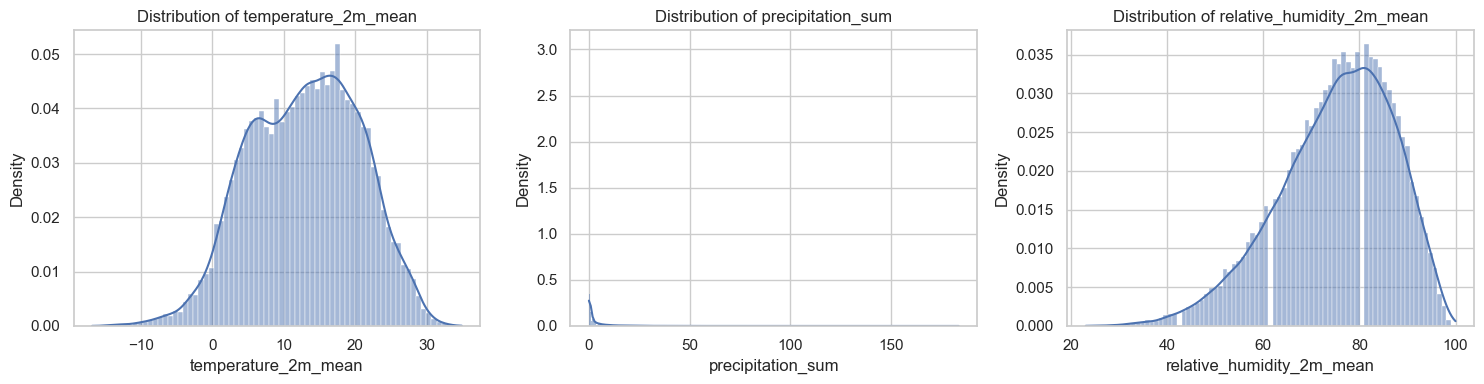

In [4]:
# Three continuous variables with three different shapes
priors = [("temperature_2m_mean", "Mean temperature (deg C)"),
          ("precipitation_sum", "Daily precipitation (mm)"),
          ("relative_humidity_2m_mean", "Mean relative humidity (%)")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, priors):
    values = df[col]
    if col == "precipitation_sum":
        # Many days have exactly 0 mm: a point mass, not a smooth density, so no smoothed curve (kde)
        # is drawn and the zero share is written on the plot. The longest 1% of the tail is not shown.
        zero_share = (values == 0).mean()
        cut = values.quantile(0.99)
        sns.histplot(values[values <= cut], binwidth=1, stat="density", ax=ax)
        ax.text(0.97, 0.95, f"{zero_share:.0%} of the days: exactly 0 mm\n(first bar also holds 0.1-0.9 mm)\nnot shown: top 1% (> {cut:.0f} mm)",
                transform=ax.transAxes, ha="right", va="top", fontsize=9)
    elif col == "relative_humidity_2m_mean":
        # given in whole percent, so every bin covers exactly 2 whole values
        sns.histplot(values, binwidth=2, kde=True, stat="density", ax=ax)
    else:
        sns.histplot(values, bins=40, kde=True, stat="density", ax=ax)
    ax.set_title(col)
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
plt.suptitle("A-priori distribution of three continuous variables (all cities, 2010-2026)", y=1.02)
plt.tight_layout()
plt.show()

# Numbers behind the plots
df[[c for c, _ in priors]].describe(percentiles=[.5, .99]).round(2)

**What the priors teach:**
- **`temperature_2m_mean`** has no single bell: mean 13.0 deg C, standard deviation 7.7, and two weak peaks (around 7 and 17 deg C). The peaks come from mixing climates: the four cool cities (Berlin, London, New York, Vancouver) have a mean of 10-12 deg C, Tokyo and Sydney 16-18. One normal distribution describes it poorly; it makes more sense to read it together with `location` and the season.
- **`precipitation_sum`** is not a smooth density: 45.5% of the days have exactly 0 mm and another 18.3% have less than 1 mm. The median is 0.2 mm, but the mean (3.2 mm) is far higher because of rare, very wet days (99th percentile 38 mm, maximum 184 mm). It is the clearest example of a variable far from a normal distribution, and it shows why the 1.0 mm threshold of the target matters: almost one day in five has some drizzle that still counts as "no rain".
- **`relative_humidity_2m_mean`** is bounded by 100% and skewed to the left: most days are humid (median 77%) and dry days form the long tail (minimum 23%). Near the upper bound a normal distribution would assign probability to impossible values above 100%.

## Target Creation: RainTomorrow

**Rule (from the assignment):** within each `location`, after sorting by `date`, `RainTomorrow = 1` if the **next day's** `precipitation_sum` is at least 1.0 mm, otherwise 0.

- `precipitation_sum` (not `rain_sum`) is used, because it includes snow.
- The 1.0 mm threshold ignores trace amounts (drizzle of 0.1 mm is not a "rainy day").
- The last day of each location has no "tomorrow", so it is removed.
- Next-day information is used **only** for the label, never as a feature (otherwise the model would see the answer - data leakage).

In [5]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["location", "date"]).reset_index(drop=True)

# shift(-1) inside each location = the value of the next row of the same city
next_precip = df.groupby("location")["precipitation_sum"].shift(-1)
next_date = df.groupby("location")["date"].shift(-1)

# The label is valid only if the next row is really the next calendar day.
# This drops the last day of each location AND the day before any gap in the data
# (e.g. a missing year), so no row gets a label from a different date.
has_tomorrow = (next_date - df["date"]).dt.days.eq(1)
print("rows without a real 'tomorrow' (last day or gap):", int((~has_tomorrow).sum()))

df["RainTomorrow"] = (next_precip >= 1.0).astype(int)
df = df[has_tomorrow].reset_index(drop=True)
df[["location", "date", "precipitation_sum", "RainTomorrow"]].head(10)

rows without a real 'tomorrow' (last day or gap): 6


,location,date,precipitation_sum,RainTomorrow
0,berlin,2010-01-01,3.2,1
1,berlin,2010-01-02,1.1,0
2,berlin,2010-01-03,0.0,0
3,berlin,2010-01-04,0.0,0
4,berlin,2010-01-05,0.0,0
5,berlin,2010-01-06,0.0,0
6,berlin,2010-01-07,0.0,0
7,berlin,2010-01-08,0.3,1
8,berlin,2010-01-09,11.3,1
9,berlin,2010-01-10,7.3,1


In [6]:
# Missing-value handling: fill with the median of the SAME city.
# A median over all cities would mix different climates (e.g. Sydney and Berlin).
# The current data has no missing values; this step makes the pipeline safe for
# future / test data that may contain gaps.
num_cols = df.select_dtypes(include=["number"]).columns.drop("RainTomorrow")
print("missing before:", int(df[num_cols].isna().sum().sum()))
df[num_cols] = df.groupby("location")[num_cols].transform(lambda s: s.fillna(s.median()))
print("missing after:", int(df.isna().sum().sum()))

missing before: 0
missing after: 0


## Prior Probabilities (2/2): the Target and the Categorical Variables

**Why:** the same idea for discrete variables. A bar chart shows the share of every value. The target `RainTomorrow` is included here, because it exists only after the target-creation step above; its prior is the most important one, because it tells us how balanced the problem is.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.3, 1.8]})

def bar_with_percent(ax, share, labels, title, xlabel):
    bars = ax.bar(labels, share.values * 100, color=sns.color_palette()[0])
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in share.values], padding=2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share of days (%)")
    ax.set_ylim(0, share.max() * 100 * 1.15)

# 1. The target
target_share = df["RainTomorrow"].value_counts(normalize=True).sort_index()
bar_with_percent(axes[0], target_share, ["No rain (0)", "Rain (1)"], "RainTomorrow (target)", "tomorrow's precipitation >= 1.0 mm")

# 2. Location
location_share = df["location"].value_counts(normalize=True).sort_index()
bar_with_percent(axes[1], location_share, location_share.index, "location", "city")
axes[1].tick_params(axis="x", rotation=30)

# 3. weather_code: horizontal bars, so the meaning of every code can be read
#    (wmo_names was defined in the data-understanding section)
code_share = df["weather_code"].value_counts(normalize=True).sort_index()
ax = axes[2]
bars = ax.barh([f"{c} - {wmo_names[c]}" for c in code_share.index], code_share.values * 100, color=sns.color_palette()[0])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in code_share.values], padding=3)
ax.invert_yaxis()
ax.set_xlim(0, code_share.max() * 100 * 1.15)
ax.set_title("weather_code (WMO code of the day)")
ax.set_xlabel("Share of days (%)")

plt.suptitle("A-priori distribution of the target and of the two categorical variables", y=1.02)
plt.tight_layout()
plt.show()

print("Share of rain days tomorrow, per city:")
print(df.groupby("location")["RainTomorrow"].mean().round(3).to_string())
print(f"\nMajority / minority ratio of the target: {target_share.max() / target_share.min():.2f} : 1")

**What the priors teach:**
- **`RainTomorrow`:** rain follows 36.2% of the days (13,380 of 36,936), so about two days in three are dry.
- **`location`:** exactly 1/6 for every city. This is not a finding but the result of our sampling - the same period was collected for each city.
- **`weather_code`:** overcast is the most common day (34.9%), then light drizzle (19.5%); clear days are rare (3.1%, and only 10.4% for the three clear or partly cloudy codes together). Only 13 of the 28 WMO codes occur.

### Is the data balanced?
**Partly.** The target is split 63.8% / 36.2%, a ratio of 1.76 : 1 - not balanced, but not extreme. The consequence is that accuracy alone is misleading: always predicting "no rain" is right 63.8% of the time. In Part B the models should also be judged by measures that look at the rain class (for example AUC, or recall and precision of "rain"). The prior also depends on the city: the share of rain days is 32.3% in Sydney and 45.2% in Vancouver, so `location` carries information about the target.

### Does the data represent reality?
**Only partly:**
- **For:** 17 years of daily values, no missing values, and a rain-day share of 32-45% that is realistic for temperate cities.
- **Against:** (1) six cities, all in temperate or subtropical climates and each with the same weight - there are no tropical, desert or polar climates, so the result should be expected to work for similar cities, not for any place on Earth; (2) every value describes a 9-25 km grid cell produced by a model, not a station measurement; (3) the source model changed twice (previous section), so the data is not one homogeneous source; (4) "rain" is defined by the 1.0 mm threshold, so the 18.3% of the days with less than 1 mm of precipitation count as dry.

## Which Training Period? A Preliminary Check

**Why:** the previous section showed that the source model changed in 2017 and in November 2024. Before deciding whether to remove the older years, we check whether the change matters for prediction. This is only a **quick, preliminary check** - the real model comparison is Part B.

**How:**
- Features: all numeric daily variables except `weather_code` (derived from precipitation, see above) and the raw wind direction, which is replaced by its sine and cosine (an angle is circular). The city is added as 0/1 columns.
- **Validation = the last 12 months** (from 2025-11-10). The models are trained only on days **before** it, so the check imitates Part B: predict a future period from the past. The validation period is entirely inside the newest model period.
- Three training periods: all years, 2017 onwards, and only after the November 2024 upgrade.
- Two different models, because different models may react differently: Gradient Boosting (flexible) and Naive Bayes (the model of the course, which treats every variable separately).
- Metric: **AUC** (0.5 = guessing, 1.0 = perfect). It is independent of the 0.5 threshold and of the class balance.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_auc_score

# Simple feature table: numeric variables, wind direction as sine / cosine, city as 0/1 columns
rad = np.deg2rad(df["wind_direction_10m_dominant"])
X = df.drop(columns=["location", "date", "weather_code", "wind_direction_10m_dominant", "RainTomorrow"])
X = X.assign(wind_dir_sin=np.sin(rad), wind_dir_cos=np.cos(rad))
X = pd.concat([X, pd.get_dummies(df["location"], dtype=float)], axis=1)
y = df["RainTomorrow"]

is_validation = df["date"] >= "2025-11-10"          # last 12 months
training_periods = {"all years (from 2010)": "2010-01-01",
                    "from 2017": "2017-01-01",
                    "after the Nov-2024 upgrade": "2024-11-13"}
models = {"Gradient Boosting": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0),
          "Naive Bayes": lambda: GaussianNB()}

rows = []
for period, start in training_periods.items():
    train = (df["date"] >= start) & ~is_validation   # only days before the validation period
    for model_name, make_model in models.items():
        model = make_model().fit(X[train], y[train])
        auc = roc_auc_score(y[is_validation], model.predict_proba(X[is_validation])[:, 1])
        rows.append({"training period": period, "training rows": int(train.sum()),
                     "model": model_name, "AUC": round(auc, 3)})

pd.DataFrame(rows).pivot(index=["training period", "training rows"], columns="model", values="AUC")

**What we learned:**
- **Removing the years before 2017 makes almost no difference:** the AUC changes by about 0.004 for both models, even though the wind variables differ by 0.6-0.7 standard deviations between the periods.
- **Keeping only the two years after the November 2024 upgrade does not help consistently:** Naive Bayes improves slightly (about +0.01), but Gradient Boosting loses about 0.04, probably because about 2,200 rows are too few examples for a flexible model.
- This was a single split with one validation year, so small differences should not be over-interpreted. The check only shows that the model change is **not a large effect on prediction**, and that the effect depends on the model.

### Decision

**All years (2010-01-01 to 2026-11-09) stay in `final_dataset.csv`, together with the `date` column. No row is removed because of the model change.** The training period will be chosen in Part B with a proper validation set.

| Option we considered | Why we did / did not choose it |
|---|---|
| Remove everything before 2017 (our first idea) | It was based on the first step only. The second step (Nov 2024) was found later, so "2017 onwards" is not homogeneous either. The check above shows no consistent benefit from removing the older years. |
| Keep only the data after Nov 2024 | It is the period closest to the future test, but it has only about 2 years, so each season appears twice. It was clearly worse for Gradient Boosting. |
| Remove or rescale the wind variables | The course staff advised to remove at most one or two variables, and only if the link to the target is both implausible and not visible in the data. Wind is physically related to rain. |
| **Keep all years, document the shifts, decide in Part B** | Removing data without evidence of benefit loses information. The `date` column allows choosing any period later with one line of code. |

**Limits we accept:** the data is not one homogeneous source, and Part B's test files will most likely come from the newest model (an assumption). Whichever training period is chosen in Part B must be justified by validation on the most recent months.

In [7]:
# Save the final dataset (features + RainTomorrow) for Part B
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)
print(f"Saved: {PROCESSED_PATH} ({df.shape[0]} rows x {df.shape[1]} columns)")
print("RainTomorrow share per city:")
df.groupby("location")["RainTomorrow"].mean().round(3)

Saved: data\processed\final_dataset.csv (36936 rows x 21 columns)
RainTomorrow share per city:


location
berlin       0.336
london       0.359
new_york     0.338
sydney       0.323
tokyo        0.366
vancouver    0.452
Name: RainTomorrow, dtype: float64